# Cartography with Matplotlib 

The story that I am telling is about the black footed ferret (Mustela Nigripes) and the prarie dog (Cynomys Ludovicanianus). The purpose of my story is to see the predator to prey relationship of a predator species that is endangered and near extinction, with their prey that is more adbundant. I wanted to see if the black footed ferret has available food, and if the population of the prarie dog is a reason to why they are near extinction. 

In [1]:
%pip install requests pandas geopandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

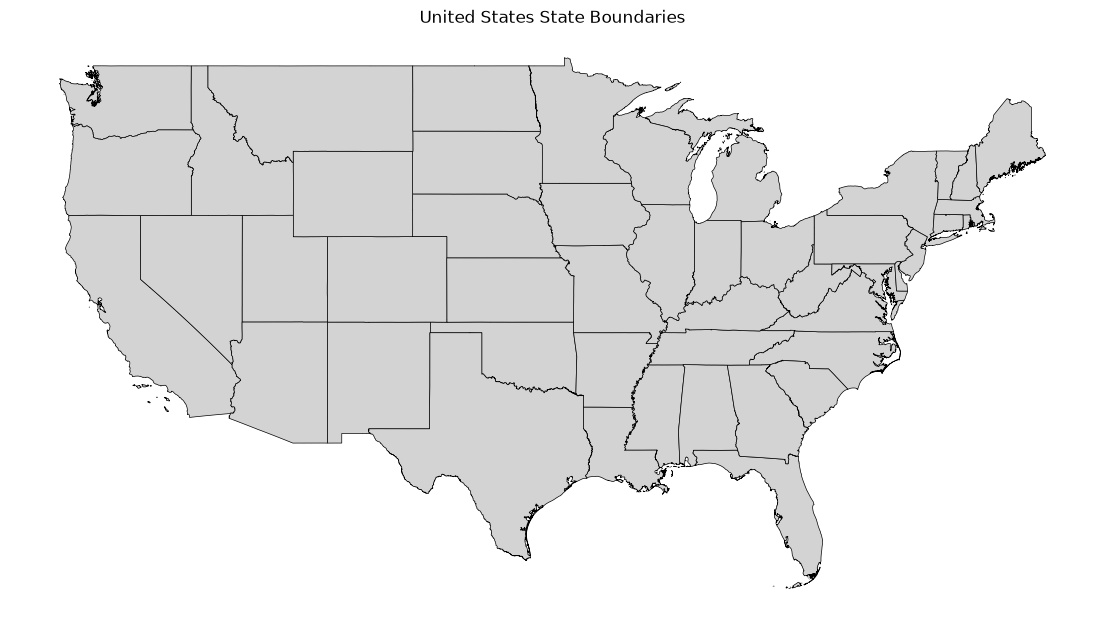

In [3]:
#read the files. Code done with AI
states = gpd.read_file(
    "cb_2018_us_state_500k (1)/cb_2018_us_state_500k.shp"
)

exclude = ["AK", "HI", "PR", "GU", "VI", "MP", "AS"]

us_states = states[
    ~states["STUSPS"].isin(exclude)
].copy()

fig, ax = plt.subplots(figsize=(14, 9))

us_states.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.5
)

ax.set_title("United States State Boundaries")
ax.set_axis_off()

plt.show()

In [4]:
species_url = "https://api.gbif.org/v1/species/match"
occurrence_url = "https://api.gbif.org/v1/occurrence/search"

In [5]:
species = [
    "Mustela nigripes",
    "Cynomys ludovicianus"
]

taxon_keys = {}

for name in species:
    response = requests.get(
        species_url,
        params={"name": name},
        timeout=30
    )
    response.raise_for_status()

    data = response.json()
    taxon_keys[name] = data["usageKey"]

print(taxon_keys)

{'Mustela nigripes': 5218985, 'Cynomys ludovicianus': 2437232}


In [6]:
#filter it to north america 
all_records = []

for name, taxon_key in taxon_keys.items():

    params = {
        "taxonKey": taxon_key,
        "continent": "NORTH_AMERICA",
        "hasCoordinate": "true",
        "hasGeospatialIssue": "false",
        "limit": 300
    }

    response = requests.get(
        occurrence_url,
        params=params,
        timeout=30
    )
    response.raise_for_status()

    data = response.json()

    records = data["results"]

    for record in records:
        record["target_species"] = name

    all_records.extend(records)

df = pd.DataFrame(all_records)
df.head()

,key,datasetKey,publishingOrgKey,datasetCategory,installationKey,hostingOrganizationKey,publishingCountry,protocol,lastCrawled,lastParsed,...,namePublishedInYear,taxonConceptID,verbatimTaxonRank,formation,member,bed,lithostratigraphicTerms,scientificNameID,parentNameUsage,infraspecificEpithet
0,5133208913,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-20T14:46:47.524+00:00,2026-10-21T05:04:17.871+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,5292872348,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-20T14:46:47.524+00:00,2026-10-21T04:37:37.166+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,5292931778,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-20T14:46:47.524+00:00,2026-10-21T04:25:09.611+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4950091206,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-20T14:46:47.524+00:00,2026-10-21T05:01:24.050+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4103339227,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-20T14:46:47.524+00:00,2026-10-21T04:53:29.722+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df = df.dropna(subset=["decimalLatitude", "decimalLongitude"])

In [8]:
df = df.dropna(
    subset=["decimalLatitude", "decimalLongitude"]
)

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(
        df["decimalLongitude"],
        df["decimalLatitude"]
    ),
    crs="EPSG:4326"
)

gdf.head()

,key,datasetKey,publishingOrgKey,datasetCategory,installationKey,hostingOrganizationKey,publishingCountry,protocol,lastCrawled,lastParsed,...,taxonConceptID,verbatimTaxonRank,formation,member,bed,lithostratigraphicTerms,scientificNameID,parentNameUsage,infraspecificEpithet,geometry
0,5133208913,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-20T14:46:47.524+00:00,2026-10-21T05:04:17.871+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POINT (-104.97701 39.8673)
1,5292872348,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-20T14:46:47.524+00:00,2026-10-21T04:37:37.166+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POINT (-103.51739 43.55829)
2,5292931778,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-20T14:46:47.524+00:00,2026-10-21T04:25:09.611+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POINT (-103.5548 43.5636)
3,4950091206,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-20T14:46:47.524+00:00,2026-10-21T05:01:24.050+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POINT (-103.55644 43.40304)
4,4103339227,50c9509d-22c7-4a22-a47d-8c48425ef4a7,28eb1a3f-1c15-4a95-931a-4af90ecb574d,[CitizenScience],997448a8-f762-11e1-a439-00145eb45e9a,28eb1a3f-1c15-4a95-931a-4af90ecb574d,US,DWC_ARCHIVE,2026-10-20T14:46:47.524+00:00,2026-10-21T04:53:29.722+00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POINT (-102.02797 43.90786)


In [9]:
#label the names of the species 

ferret = gdf[
    gdf["target_species"] == "Mustela nigripes"
].copy()

prairie_dog = gdf[
    gdf["target_species"] == "Cynomys ludovicianus"
].copy()

ferret.to_file("black_footed_ferret.geojson")
prairie_dog.to_file("black_tailed_prairie_dog.geojson")

In [10]:
ferret = gpd.read_file("black_footed_ferret.geojson")

prairie_dog = gpd.read_file("black_tailed_prairie_dog.geojson")

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/geopandas/io/file.py:582: UserWarning: Could not parse column 'dynamicProperties' as JSON; leaving as string
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/geopandas/io/file.py:582: UserWarning: Could not parse column 'previousIdentifications' as JSON; leaving as string
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)


In [11]:
print(ferret.head())
print(prairie_dog.head())

          key                            datasetKey  \
0  5133208913  50c9509d-22c7-4a22-a47d-8c48425ef4a7   
1  5292872348  50c9509d-22c7-4a22-a47d-8c48425ef4a7   
2  5292931778  50c9509d-22c7-4a22-a47d-8c48425ef4a7   
3  4950091206  50c9509d-22c7-4a22-a47d-8c48425ef4a7   
4  4103339227  50c9509d-22c7-4a22-a47d-8c48425ef4a7   

                       publishingOrgKey   datasetCategory  \
0  28eb1a3f-1c15-4a95-931a-4af90ecb574d  [CitizenScience]   
1  28eb1a3f-1c15-4a95-931a-4af90ecb574d  [CitizenScience]   
2  28eb1a3f-1c15-4a95-931a-4af90ecb574d  [CitizenScience]   
3  28eb1a3f-1c15-4a95-931a-4af90ecb574d  [CitizenScience]   
4  28eb1a3f-1c15-4a95-931a-4af90ecb574d  [CitizenScience]   

                        installationKey                hostingOrganizationKey  \
0  997448a8-f762-11e1-a439-00145eb45e9a  28eb1a3f-1c15-4a95-931a-4af90ecb574d   
1  997448a8-f762-11e1-a439-00145eb45e9a  28eb1a3f-1c15-4a95-931a-4af90ecb574d   
2  997448a8-f762-11e1-a439-00145eb45e9a  28eb1a3f-1c15-4a95

In [12]:
print("Black-footed ferret:", len(ferret))
print("Black-tailed prairie dog:", len(prairie_dog))

Black-footed ferret: 232
Black-tailed prairie dog: 300


In [13]:
#count 
ferret = ferret.to_crs(us_states.crs)

prairie_dog = prairie_dog.to_crs(us_states.crs)

In [14]:
#clip to the US to the lower 48 
ferret_us = gpd.clip(ferret, us_states)

prairie_dog_us = gpd.clip(prairie_dog, us_states)

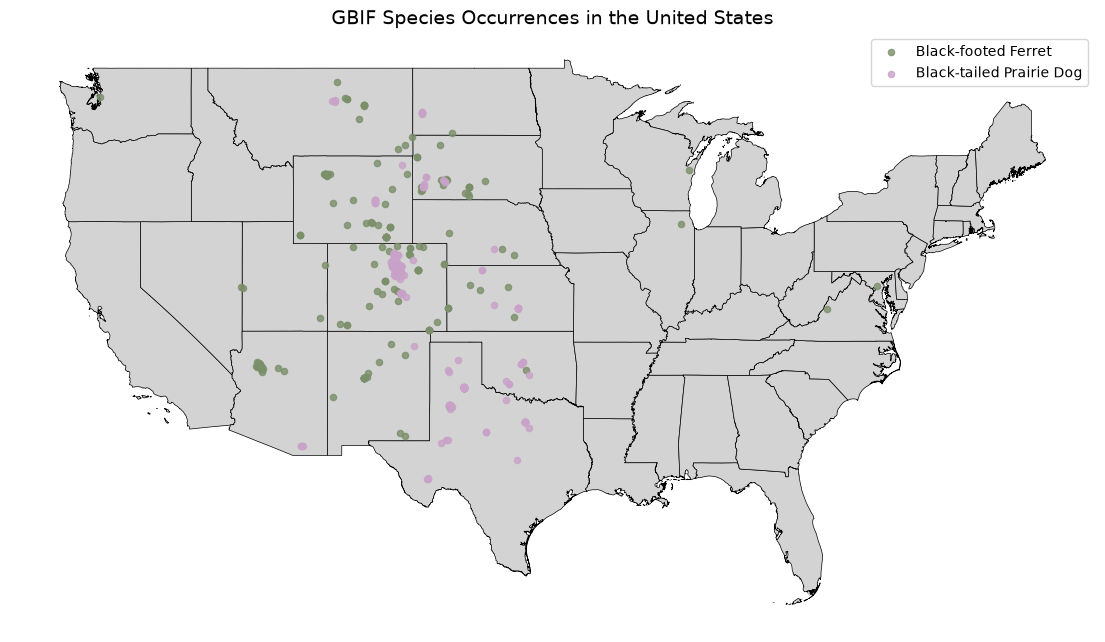

In [15]:
fig, ax = plt.subplots(figsize=(14, 9))

# Plot US states
us_states.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.5
)

# Plot black-footed ferrets
ferret_us.plot(
    ax=ax,
    color="#7A8F6A",
    markersize=20,
    alpha=0.8,
    label="Black-footed Ferret"
)

# Plot black-tailed prairie dogs
prairie_dog_us.plot(
    ax=ax,
    color="#C8A2C8",
    markersize=20,
    alpha=0.8,
    label="Black-tailed Prairie Dog"
)

ax.set_title(
    "GBIF Species Occurrences in the United States",
    fontsize=14
)

ax.legend()
ax.set_axis_off()

plt.show()

In [16]:
print("Ferret observations in US:", len(ferret_us))
print("Prairie dog observations in US:", len(prairie_dog_us))

Ferret observations in US: 210
Prairie dog observations in US: 300


In [17]:
# Spatially join prairie dog observations to states
prairie_join = gpd.sjoin(
    prairie_dog_us,
    us_states[["STUSPS", "geometry"]],
    how="inner",
    predicate="within"
)

# Count observations by state
prairie_counts = prairie_join.groupby("STUSPS").size()

# Add counts to state polygons
states_prairie = us_states.copy()

states_prairie["prairie_count"] = (
    states_prairie["STUSPS"]
    .map(prairie_counts)
    .fillna(0)
    .astype(int)
)

states_prairie[["NAME", "prairie_count"]].head()

,NAME,prairie_count
0,Mississippi,0
1,North Carolina,0
2,Oklahoma,8
3,Virginia,0
4,West Virginia,0


In [18]:
%pip install mapclassify

Note: you may need to restart the kernel to use updated packages.


# Four Chloropleth Maps

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/mapclassify/classifiers.py:1767: UserWarning: Not enough unique values in array to form 5 classes. Setting k to 3.
  self.bins = quantile(y, k=k)


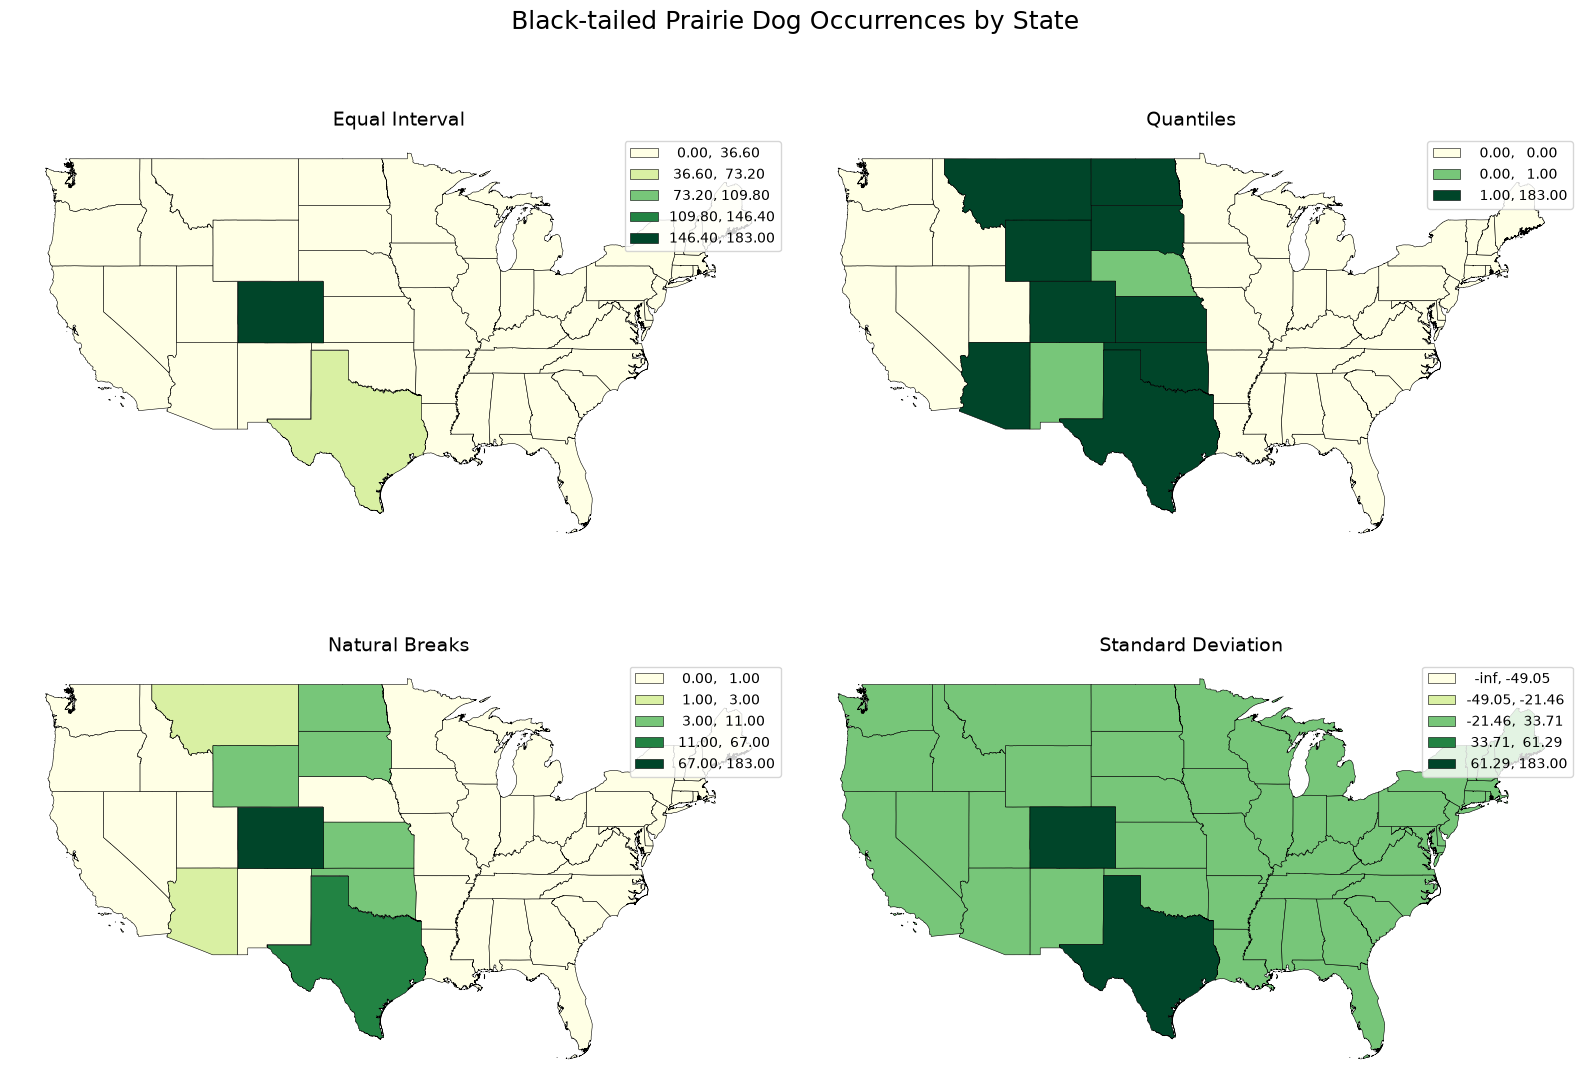

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

schemes = [
    ("equal_interval", "Equal Interval"),
    ("quantiles", "Quantiles"),
    ("natural_breaks", "Natural Breaks"),
    ("std_mean", "Standard Deviation")
]

for ax, (scheme, title) in zip(axes.flat, schemes):

    states_prairie.plot(
        column="prairie_count",
        cmap="YlGn",
        scheme=scheme,
        k=5,
        legend=True,
        edgecolor="black",
        linewidth=0.4,
        ax=ax
    )

    ax.set_title(title, fontsize=14)
    ax.set_axis_off()

plt.suptitle(
    "Black-tailed Prairie Dog Occurrences by State",
    fontsize=18
)

plt.tight_layout()
plt.show()

**Also add a short description about the benefits and limitations of classification schemes for studying species distribution in the landscape.**

The benefits and limitations of classification schemes for studying species distribution depends on the objectives of a project/what you want to see. 

1) Equal interval is beneifiial if you want to see which states the black footed ferret is concentrated in. However a limitation to this is is discounts the other states that the black footed ferret is located in.
2) Quantiles is beneficial if you want to see the states that the prarie dog is located in, and highlights the two main states that the ferret is less liklely to be in. 
3) Natrual Breaks is beneficial to see the main state that the prarie dog is concentrated in while also seeing the surrounding states that also have the ferret in smaller concentrations. This is type of classificiation is limited because the rest of the States that are classified as 0, also are classified if there is 1, so North Carolina- where the ferret is least likeley to be in(0)- is classified the same as Nebraska that has 1. 
4) Standard deviation is a beneficial classification if you want to see the concentrations by seeing where the data is skewed. So texas and Colorado. However it is limited just like the Natural Breaks, where the states that have 0 observations of ferrets are the same color as states that have more than 0. 



In [20]:
# Count ferret observations by state
ferret_join = gpd.sjoin(
    ferret_us,
    us_states[["STUSPS", "geometry"]],
    how="inner",
    predicate="within"
)

ferret_counts = ferret_join.groupby("STUSPS").size()

# Combine both species into one GeoDataFrame
states_bivariate = states_prairie.copy()

states_bivariate["ferret_count"] = (
    states_bivariate["STUSPS"]
    .map(ferret_counts)
    .fillna(0)
    .astype(int)
)

AI Based code to make a Bivariate map for fun

In [21]:

# Rank-based classes (0, 1, 2)
states_bivariate["ferret_class"] = pd.qcut(
    states_bivariate["ferret_count"].rank(method="first"),
    q=3,
    labels=False
)

states_bivariate["prairie_class"] = pd.qcut(
    states_bivariate["prairie_count"].rank(method="first"),
    q=3,
    labels=False
)

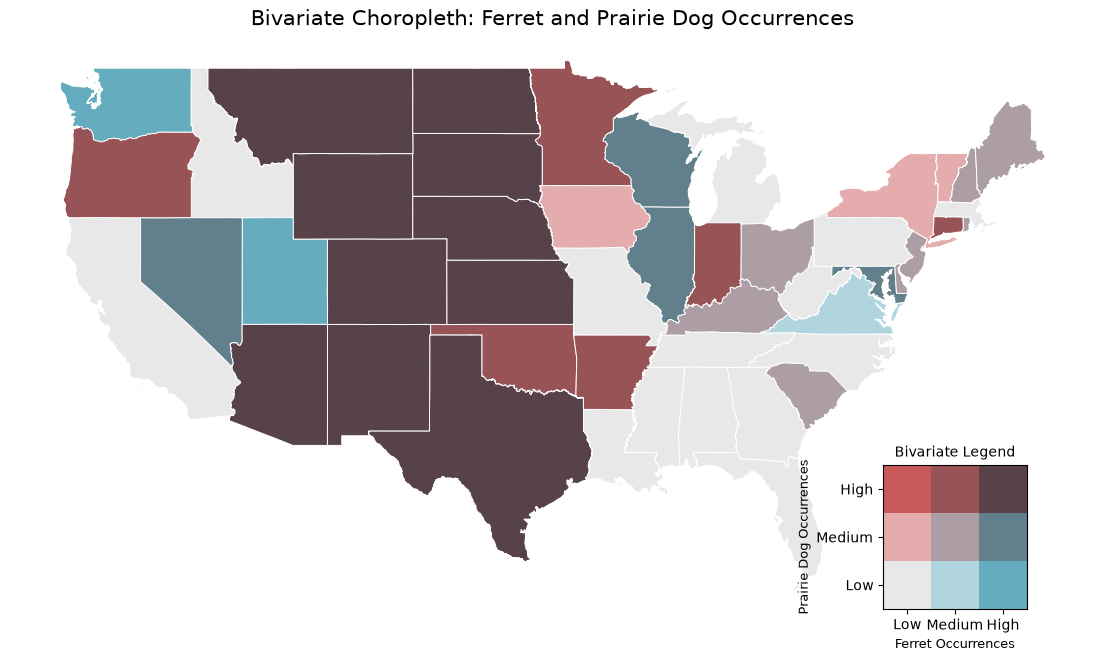

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import to_rgb

# Bivariate color palette
colors = np.array([
    ["#e8e8e8", "#b0d5df", "#64acbe"],
    ["#e4acac", "#ad9ea5", "#627f8c"],
    ["#c85a5a", "#985356", "#574249"]
])

# Assign colors to states
states_bivariate["color"] = [
    colors[p, f]
    for p, f in zip(
        states_bivariate["prairie_class"],
        states_bivariate["ferret_class"]
    )
]

# Create figure
fig, ax = plt.subplots(figsize=(14, 9))

# Plot states
states_bivariate.plot(
    ax=ax,
    color=states_bivariate["color"],
    edgecolor="white",
    linewidth=0.7
)

ax.set_title(
    "Bivariate Choropleth: Ferret and Prairie Dog Occurrences",
    fontsize=15
)
ax.set_axis_off()

# Convert HEX colors to RGB for the legend
rgb_colors = np.array([
    [to_rgb(c) for c in row]
    for row in colors
])

# Add legend to the same figure
legend_ax = fig.add_axes([0.72, 0.18, 0.16, 0.16])

legend_ax.imshow(rgb_colors, origin="lower")

legend_ax.set_xticks([0, 1, 2])
legend_ax.set_yticks([0, 1, 2])

legend_ax.set_xticklabels(["Low", "Medium", "High"])
legend_ax.set_yticklabels(["Low", "Medium", "High"])

legend_ax.set_xlabel("Ferret Occurrences", fontsize=9)
legend_ax.set_ylabel("Prairie Dog Occurrences", fontsize=9)
legend_ax.set_title("Bivariate Legend", fontsize=10)

plt.show()